# Is Good Food Really Enough to Get 5 Stars on Google Maps?

**Author** : Nathan Tessot

**Date** : April 2026

📄 The written report is in [`report/Good_Food_5_Stars_Google_Maps_Tessot.pdf`](report/Good_Food_5_Stars_Google_Maps_Tessot.pdf).

## 1. Introduction

The way reputation works on Google Maps has always been a major concern for restaurant owners since the platform became a standard for finding places to eat **(Li & Hecht, 2020)**. More generally, in the digital economy, online reviews significantly shape an establishment's reputation and have been shown to have a measurable impact on revenue **(Luca, 2016)**.


Beyond the digital context, understanding customer reviews also requires examining the broader theory of consumer perception, which suggests that the perceived value of an experience is a complex trade-off between price, quality, and personal benefit **(Zeithaml, 1988)**.


The case of Google Reviews is particularly interesting because ratings truly form the digital identity of an establishment. While exceptional food is traditionally the main reason people go to a restaurant, a dining experience is shaped by many other factors. Knowing that small details like a friendly waiter, a nice ambiance, or the perceived value for money can greatly influence a customer's experience, it’s interesting to investigate the causal relationships between these elements and the final score a customer decides to leave, while analyzing its global positive or negative sentiment.


**Therefore, the main question we want to answer is: What are the aspects of a dining experience that influence a good rating on Google Maps the most?** 

Based on this, we can formulate several predictions:

***- Prediction 1 :*** *Food quality is the strongest predictor of a high rating, significantly outweighing other factors.*

***- Prediction 2 :*** *People tend to give higher ratings to restaurants that are already popular and have a large number of reviews.*

***- Prediction 3 :*** *Since human interactions are still important, service quality is a strong factor explaining a positive sentiment.*

***- Prediction 4 :*** *The restaurant setting, like its atmosphere and cleanliness, are strong predictors of a positive sentiment.*


## 2. Library import

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
import networkx as nx

## 3. Directed Acyclic Graph

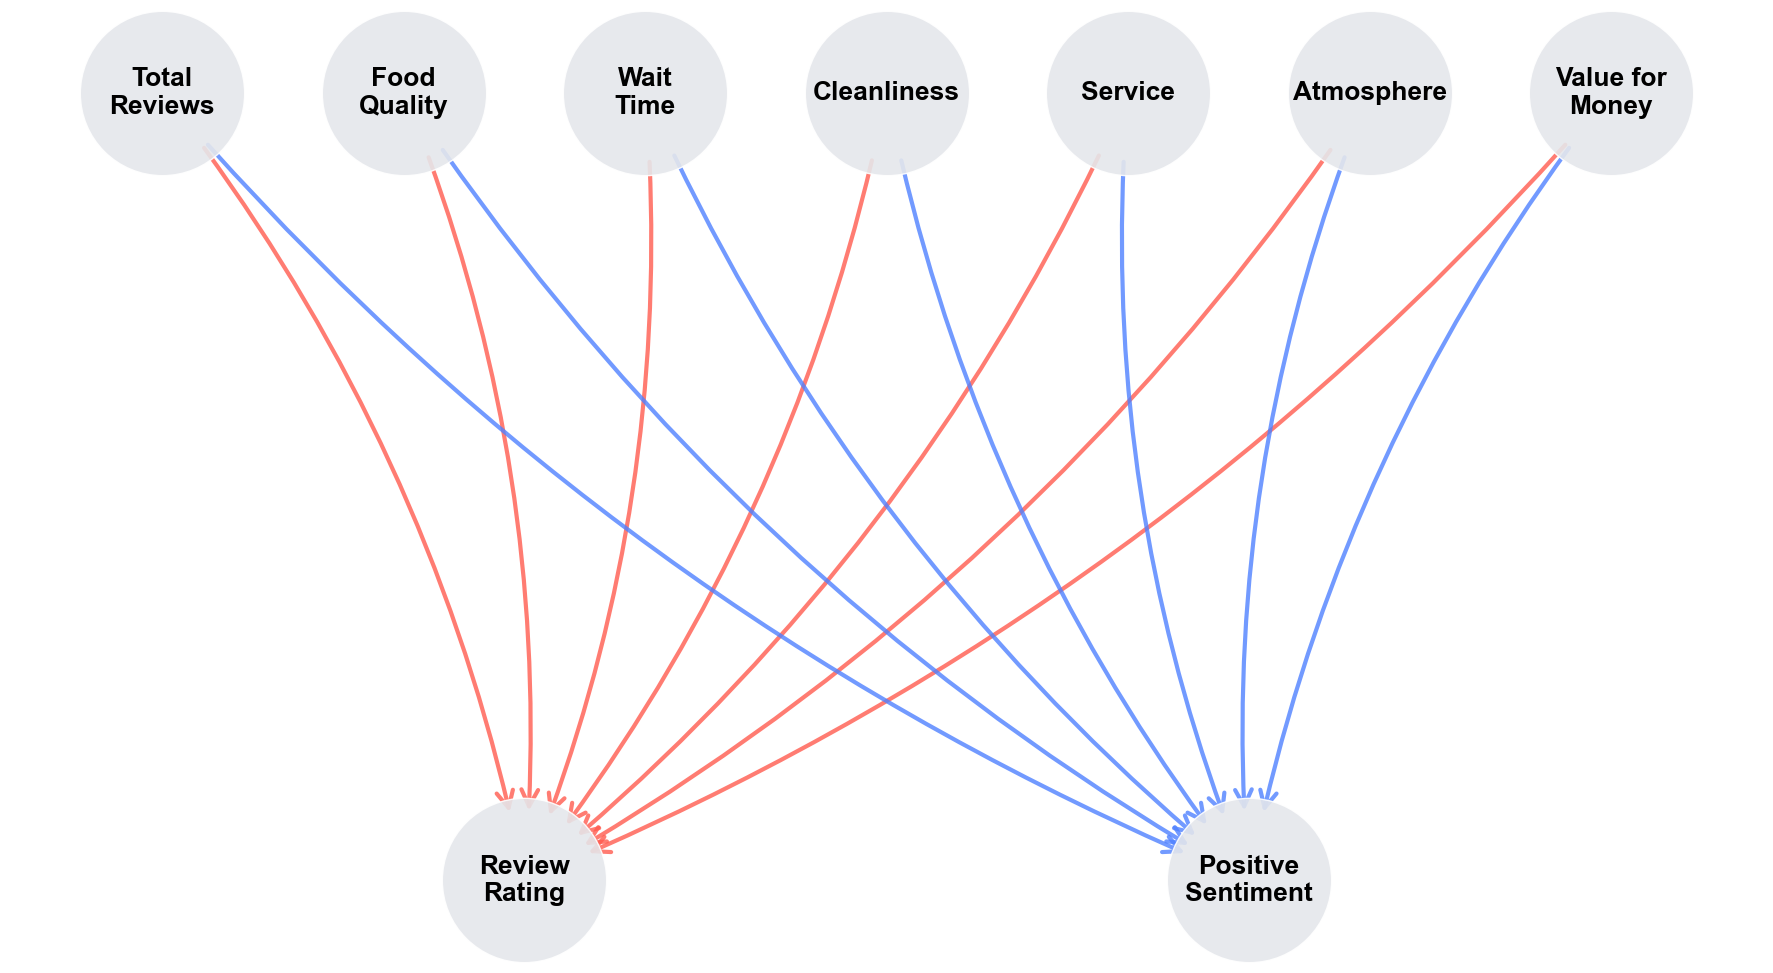

In [38]:
dag = nx.DiGraph()

top_nodes = [
    "Total\nReviews", "Food\nQuality", "Wait\nTime", 
    "Cleanliness", "Service", "Atmosphere", "Value for\nMoney"
]
target_nodes = ["Review\nRating", "Positive\nSentiment"]

dag.add_nodes_from(top_nodes + target_nodes)

rating_edges = [(top_node, "Review\nRating") for top_node in top_nodes]
sentiment_edges = [(top_node, "Positive\nSentiment") for top_node in top_nodes]

dag.add_edges_from(rating_edges + sentiment_edges)

pos = {}
num_top = len(top_nodes)
for i, node in enumerate(top_nodes):
    pos[node] = (i - (num_top - 1) / 2.0, 1)

pos["Review\nRating"] = (-1.5, -1)
pos["Positive\nSentiment"] = (1.5, -1)

plt.figure(figsize=(18, 10))
nx.draw_networkx_nodes(dag, pos, node_color='#E5E7EB', node_size=14000, edgecolors='white', alpha=0.9)
nx.draw_networkx_labels(dag, pos, font_size=19, font_weight="bold", font_color='black')

nx.draw_networkx_edges(dag, pos, edgelist=rating_edges, arrowstyle="->", arrowsize=30, 
                       edge_color="#ff5b4f", width=3, alpha=0.8, node_size=10000, connectionstyle="arc3,rad=-0.12")
nx.draw_networkx_edges(dag, pos, edgelist=sentiment_edges, arrowstyle="->", arrowsize=30, 
                       edge_color="#4f81ff", width=3, alpha=0.8, node_size=10000, connectionstyle="arc3,rad=0.12")
                       
plt.axis('off')
plt.tight_layout()
plt.show()


## 4. Data import

In [ ]:
df = pd.read_csv("data/reviews_annotated.csv")
display(df)

## 5. Data manipulation

In [40]:
df = df.drop(columns=['query_originale','google_name','adress','latitude','longitude','average_rating','review_text','review_date','justification'], errors='ignore')
df

,total_reviews,review_rating,is_positive,food_quality_score,price_quality_score,service_score,wait_time_score,atmosphere_score,cleanliness_score
0,1044.0,1.0,0,0,0,-2,0,-2,-2
1,454.0,1.0,0,-1,-2,0,0,0,0
2,11.0,1.0,0,0,0,-1,0,0,0
3,218.0,1.0,0,-2,-2,1,0,0,0
4,711.0,1.0,0,-2,-2,-2,0,0,0
...,...,...,...,...,...,...,...,...,...
4995,1684.0,5.0,1,2,0,1,0,0,0
4996,342.0,5.0,1,2,0,2,0,0,0
4997,1008.0,5.0,1,2,0,2,0,1,2
4998,828.0,5.0,1,2,0,2,1,0,0


## 6. Data description

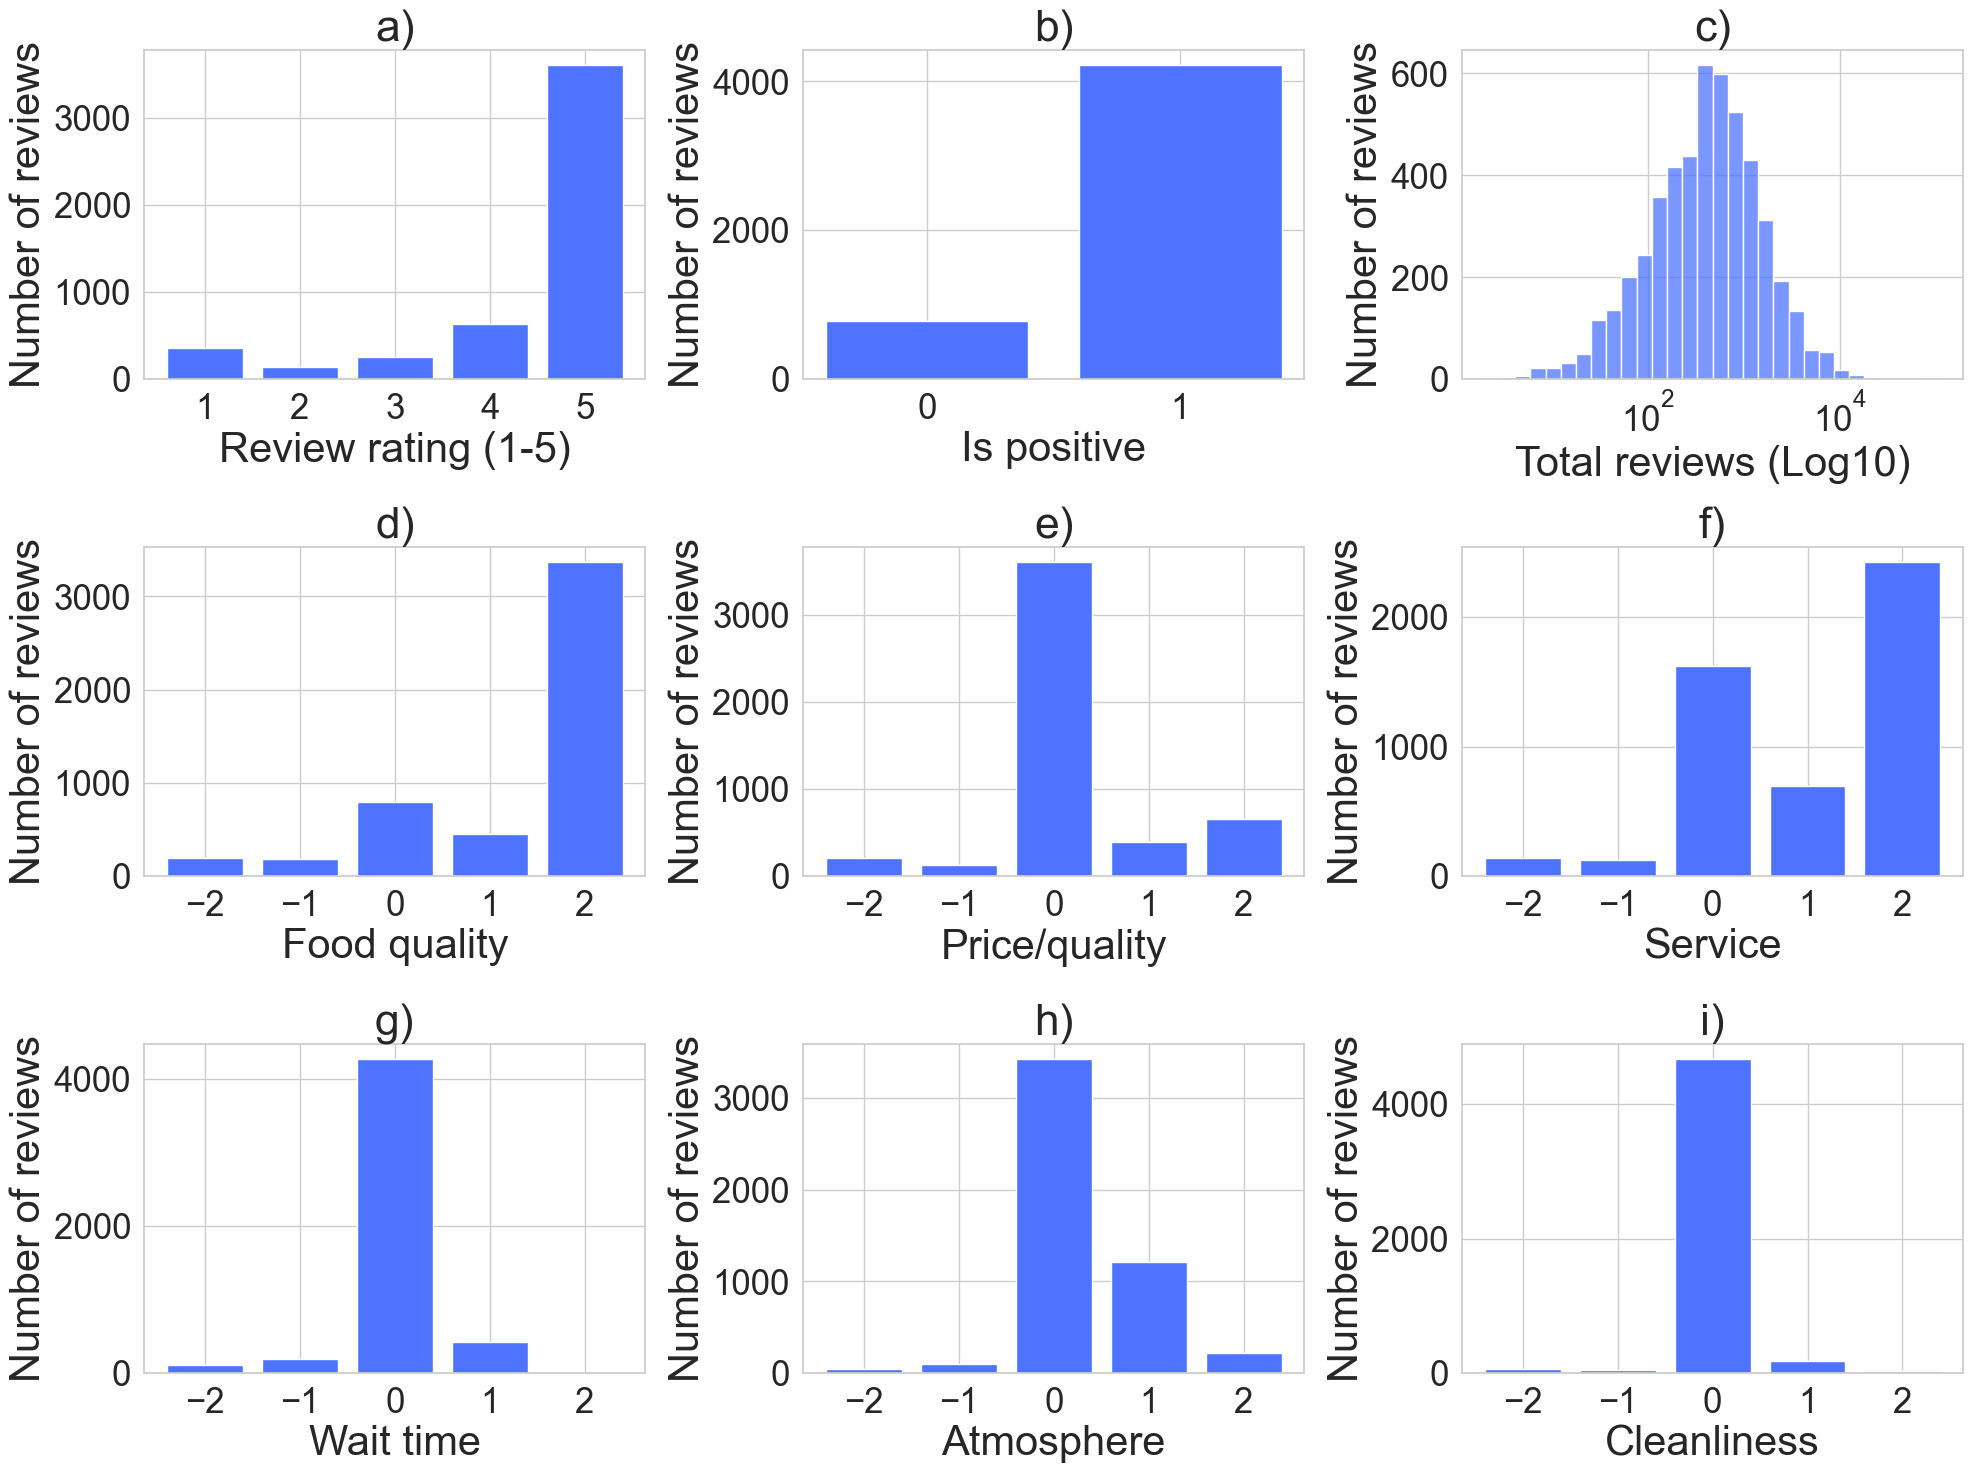

In [ ]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Helvetica']

sns.set(style="whitegrid", font_scale=1.3)

fig, axs = plt.subplots(3, 3, figsize=(20, 15))
letters = list("abcdefghi")
axs_flat = axs.flatten()
tick_size = 25

# a) review_rating
counts_a = df["review_rating"].value_counts().sort_index()
axs_flat[0].bar(counts_a.index.astype(int), counts_a.values, color="#4e74ff", edgecolor="white")
axs_flat[0].set_xlabel("Review rating (1-5)", fontsize=30)
axs_flat[0].set_ylabel("Number of reviews", fontsize=30)
axs_flat[0].set_title(f"{letters[0]})", fontsize=32)
axs_flat[0].set_xticks([1, 2, 3, 4, 5])
axs_flat[0].tick_params(axis='both', which='major', labelsize=tick_size) # FORCE LA TAILLE ICI

# b) is_positive
counts_b = df["is_positive"].value_counts().sort_index()
axs_flat[1].bar(counts_b.index.astype(int), counts_b.values, color="#4e74ff", edgecolor="white")
axs_flat[1].set_xlabel("Is positive", fontsize=30)
axs_flat[1].set_ylabel("Number of reviews", fontsize=30)
axs_flat[1].set_title(f"{letters[1]})", fontsize=32)
axs_flat[1].set_xticks([0, 1])
axs_flat[1].tick_params(axis='both', which='major', labelsize=tick_size) # FORCE LA TAILLE ICI

# c) total_reviews
sns.histplot(df["total_reviews"] + 1, log_scale=True, bins=30, ax=axs_flat[2], color="#4e74ff", edgecolor="white")
axs_flat[2].set_xlabel("Total reviews (Log10)", fontsize=30)
axs_flat[2].set_ylabel("Number of reviews", fontsize=30)
axs_flat[2].set_title(f"{letters[2]})", fontsize=32)
axs_flat[2].tick_params(axis='both', which='major', labelsize=tick_size) # FORCE LA TAILLE ICI

# d-i) 6 scores
scores = [
    ("food_quality_score", "Food quality"),
    ("price_quality_score", "Price/quality"),
    ("service_score", "Service"),
    ("wait_time_score", "Wait time"),
    ("atmosphere_score", "Atmosphere"),
    ("cleanliness_score", "Cleanliness")
]

for i, (var, label) in enumerate(scores):
    idx = i + 3
    counts = df[var].value_counts().sort_index()
    axs_flat[idx].bar(counts.index, counts.values, color="#4e74ff", edgecolor="white")
    axs_flat[idx].set_xlabel(f"{label}", fontsize=30)
    axs_flat[idx].set_ylabel("Number of reviews", fontsize=30)
    axs_flat[idx].set_title(f"{letters[idx]})", fontsize=32)
    axs_flat[idx].set_xticks([-2, -1, 0, 1, 2])
    axs_flat[idx].tick_params(axis='both', which='major', labelsize=tick_size) # FORCE LA TAILLE ICI

plt.tight_layout()
plt.show()


## 7. Data Standardization

In [42]:
# Standardize all variables
scaler = StandardScaler()
X = scaler.fit_transform(df)
df_scaled = pd.DataFrame(X, columns=df.columns)


## 8. Data modelling

We computed the following linear models:

$ReviewRating_{i} = \beta_{0} + \beta_{1} FoodQuality_{i} + \beta_{2} PriceQuality_{i} + \beta_{3} Service_{i} + \beta_{4} WaitTime_{i} + \beta_{5} Atmosphere_{i} + \beta_{6} Cleanliness_{i} + \beta_{7} TotalReviews_{i} + \epsilon_{i}$

$IsPositive_{i} = \beta_{0} + \beta_{1} FoodQuality_{i} + \beta_{2} PriceQuality_{i} + \beta_{3} Service_{i} + \beta_{4} WaitTime_{i} + \beta_{5} Atmosphere_{i} + \beta_{6} Cleanliness_{i} + \beta_{7} TotalReviews_{i} + \epsilon_{i}$


In [43]:
# Model 1: review_rating as dependent variable
model1 = smf.ols(
    formula='review_rating ~ food_quality_score + price_quality_score + service_score + wait_time_score + atmosphere_score + cleanliness_score + total_reviews',
    data=df_scaled
).fit()

print("=" * 80)
print("MODEL 1 — Dependent variable: review_rating")
print("=" * 80)
print(model1.summary())


MODEL 1 — Dependent variable: review_rating
                            OLS Regression Results                            
Dep. Variable:          review_rating   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                     1089.
Date:                Wed, 01 Apr 2026   Prob (F-statistic):               0.00
Time:                        09:03:14   Log-Likelihood:                -4777.0
No. Observations:                5000   AIC:                             9570.
Df Residuals:                    4992   BIC:                             9622.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

In [44]:
# Model 2: is_positive as dependent variable
model2 = smf.ols(
    formula='is_positive ~ food_quality_score + price_quality_score + service_score + wait_time_score + atmosphere_score + cleanliness_score + total_reviews',
    data=df_scaled
).fit()

print("=" * 80)
print("MODEL 2 — Dependent variable: is_positive")
print("=" * 80)
print(model2.summary())


MODEL 2 — Dependent variable: is_positive
                            OLS Regression Results                            
Dep. Variable:            is_positive   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     992.2
Date:                Wed, 01 Apr 2026   Prob (F-statistic):               0.00
Time:                        09:03:14   Log-Likelihood:                -4915.0
No. Observations:                5000   AIC:                             9846.
Df Residuals:                    4992   BIC:                             9898.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

## 9. Forest plot

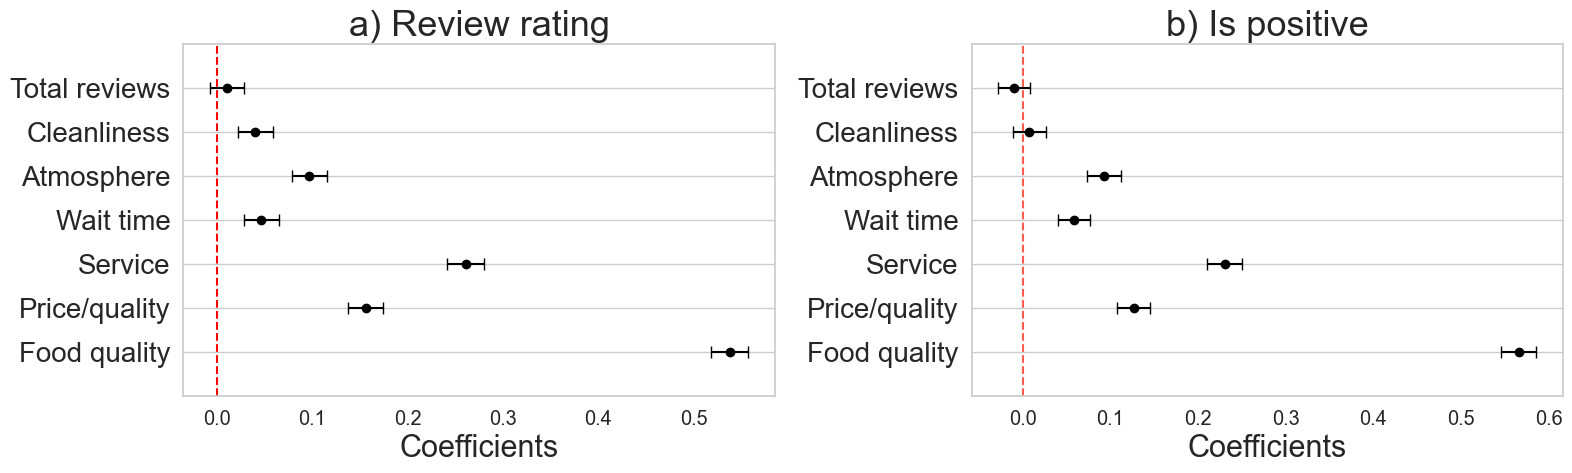

In [45]:
sns.set(style="whitegrid", context="notebook", font_scale=1.3)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# --- Forest Plot 1: review_rating ---
coefs1 = model1.params[1:]
ci1 = (model1.conf_int(alpha=0.05)[1] - model1.conf_int(alpha=0.05)[0]) / 2
ci1 = ci1[1:]
variables1 = ["Food quality", "Price/quality", "Service", "Wait time", "Atmosphere", "Cleanliness", "Total reviews"]
y_pos1 = range(1, len(variables1) + 1)

axs[0].errorbar(coefs1, y_pos1, xerr=ci1, fmt='o', color='black', markerfacecolor='black', ecolor='black', capsize=4)
axs[0].set_yticks(list(y_pos1))
axs[0].set_yticklabels(variables1, fontsize=20)
axs[0].axvline(x=0, linestyle='--', color='red')
axs[0].set_xlabel("Coefficients", fontsize=22)
axs[0].set_title("a) Review rating", fontsize=26)
axs[0].set_ylim(0, len(variables1) + 1)
axs[0].grid(axis='x')

# --- Forest Plot 2: is_positive ---
coefs2 = model2.params[1:]
ci2 = (model2.conf_int(alpha=0.05)[1] - model2.conf_int(alpha=0.05)[0]) / 2
ci2 = ci2[1:]
variables2 = variables1
y_pos2 = range(1, len(variables2) + 1)

axs[1].errorbar(coefs2, y_pos2, xerr=ci2, fmt='o', color='black', markerfacecolor='black', ecolor='black', capsize=4)
axs[1].set_yticks(list(y_pos2))
axs[1].set_yticklabels(variables2, fontsize=20)
axs[1].axvline(x=0, linestyle='--', color='#ff5b4f')
axs[1].set_xlabel("Coefficients", fontsize=22)
axs[1].set_title("b) Is positive", fontsize=26)
axs[1].set_ylim(0, len(variables2) + 1)
axs[1].grid(axis='x')

plt.tight_layout()
plt.show()
